# SPC daily climatology as a reference forecast, on 80-km equal-area cells (CSV output)

The daily tornado climatology polygons (`torday30_{jjj}_{event}.json`) from SPC's climatology data viewer (https://www.spc.noaa.gov/climo/dataviewer/; files from David Harrison) are verified here **as forecasts**, in the same way as the SPC outlooks (`do_verf_outlooks_tiles.ipynb`) and the PPH/CIG analyses (`do_verf_pph_tiles.ipynb`). The output has the same columns. Section 9 then uses these files as the **reference** in skill scores for the outlooks and the PPH.

**The climo files** (checked on the copies in Downloads/SPC_climo):
- Four sets of 366 files. `any` is labeled "tornado within 25 miles". `1`, `2` and `3` are labeled F/EF1+, F/EF2+ and F/EF3+.
- Probabilities are in **percent** and are much lower than the outlooks': highest contour 3.6% (any), 2.3% (EF1+), 1.0% (EF2+) and 0.55% (EF3+).
- Each feature is one exclusive band (no overlap with the next level), labeled by its lower edge in `title` (e.g. `'0.40 '`). Levels with no area have `null` geometry.
- `ValidStart`/`ValidEnd` are 00Z–00Z dates in 2020 (a leap year).

**Choices to be aware of** (settings cell):
- **Calendar day.** A convective day D uses file `jjj` = D's day of year on a 366-day calendar, as in `do_verf_climo.ipynb`. The file's own `ValidStart` is one day earlier than that. With 30-day smoothing the difference is small, but confirm which is intended.
- **Value of each band.** The default uses the lower edge (the label), as your notebook did, which makes climo slightly low. `'mid'` uses the middle of the band. The top band uses the file's `max` property as its upper edge.
- **Below the lowest contour** (< 0.10% for `any`): 0 by default.
- **Valid window.** Climo describes a whole day, but for skill against the 1630 outlook it is verified over the same 16:30Z–12Z window, so both use identical observations. Climo will look slightly high in that window. `CLIMO_SCALE` can scale it down.

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import requests
import matplotlib.pyplot as plt

## Settings

In [2]:
DATES    = pd.date_range('2026-03-03', '2026-06-30', freq='D')    # convective days
HHMM     = '1630'                    # verify over the same window as the 1630 outlook: 16:30Z to 12Z

CRS_EQ   = 'EPSG:5070'
CELL_M   = 80_000.0
BUFFER_M = 40_000.0
GRID     = 1.0

HAZARDS = {'torn': dict(event_type='Tornado', thresholds=[0, 1, 2, 3, 4],
                        labels=['ef0', 'ef1', 'ef2', 'ef3', 'ef4'])}

# climo file suffix -> the observation column it is a forecast of
CLIMO_EVENTS = {'any': 'obs_ef0', '1': 'obs_ef1', '2': 'obs_ef2', '3': 'obs_ef3'}
BAND_VALUE   = 'lower'      # 'lower' = the label (lower edge of the band), 'mid' = middle of the band
BELOW_LOWEST = 0.0          # probability (%) given to the area below the lowest contour
CLIMO_SCALE  = 1.0          # multiply climo probabilities (e.g. < 1 to allow for the shorter window)

DATA      = os.path.expanduser('~/Downloads/PPH_geojsons')
USA_FILE  = f'{DATA}/usa_outline.geojson'
REG_FILE  = f'{DATA}/bukovsky_regions_groups.geojson'
CLIMO_DIR = os.path.expanduser('~/Downloads/SPC_climo/json_torday30_conus')
OUT_DIR   = os.path.expanduser('~/datasets/climo_tiles_2026')
OTLK_OUT  = os.path.expanduser('~/datasets/outlook_tiles_2026')    # outputs of the other two notebooks,
PPH_OUT   = os.path.expanduser('~/datasets/pph_tiles_2026')        # used in section 9
# Storm Events from NCEI: https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/ (check for the latest c-date)
STORM_EVENTS = os.path.expanduser('~/datasets/storm_events/StormEvents_details-ftp_v1.0_d2026_c20261119.csv.gz')   # local copy; the URL also works
os.makedirs(OUT_DIR, exist_ok=True)

def climo_jjj(day):
    # day of year on a 366-day calendar (as in do_verf_climo.ipynb): in non-leap years, add 1 from March on
    if day.is_leap_year or day.month < 3:
        return day.dayofyear
    return day.dayofyear + 1

def climo_path(day, event):
    return os.path.join(CLIMO_DIR, f'torday30_{climo_jjj(day):03d}_{event}.json')

def window(day):
    return (day + pd.Timedelta(hours=int(HHMM[:2]), minutes=int(HHMM[2:])), day + pd.Timedelta(days=1, hours=12))

## 2. Storm Events reports

Storm Events times are local standard time, and `CZ_TIMEZONE` gives the offset: `CST-6` means UTC = local + 6 h. The offset is read from the string itself, so every zone is handled; your original cells dropped MST-7. Anything that can't be parsed is counted and reported.

The magnitude `mag` is the EF rating for tornadoes (EFU = 0), knots for wind, and inches for hail. Events below the lowest threshold, or with no magnitude, are left out and counted.

In [3]:
def tz_offset_hours(tz):
    # Hours to ADD to Storm Events local time to get UTC: 'CST-6' -> 6, 'AKST-9' -> 9, 'GST10' -> -10
    m = re.fullmatch(r'([A-Za-z]+)(-?)(\d+)', str(tz).strip())
    if m is None:
        return np.nan
    n = float(m.group(3))
    return n if m.group(2) == '-' else -n

EF = {'EFU': 0, 'EF0': 0, 'EF1': 1, 'EF2': 2, 'EF3': 3, 'EF4': 4, 'EF5': 5}

def storm_events_table(storm, haz):
    spec = HAZARDS[haz]
    d = storm[storm.EVENT_TYPE == spec['event_type']].copy()
    off_h = d.CZ_TIMEZONE.map(tz_offset_hours)
    off = pd.to_timedelta(off_h, unit='h')
    d['t0'] = pd.to_datetime(d.BEGIN_DATE_TIME, format='%d-%b-%y %H:%M:%S') + off
    d['t1'] = pd.to_datetime(d.END_DATE_TIME,   format='%d-%b-%y %H:%M:%S') + off
    d['lon0'], d['lat0'] = d.BEGIN_LON, d.BEGIN_LAT
    d['lon1'], d['lat1'] = d.END_LON.fillna(d.BEGIN_LON), d.END_LAT.fillna(d.BEGIN_LAT)
    d['mag'] = d.TOR_F_SCALE.map(EF) if haz == 'torn' else pd.to_numeric(d.MAGNITUDE, errors='coerce')
    bad_t = d.t1 < d.t0
    d.loc[bad_t, 't1'] = d.loc[bad_t, 't0']
    no_tz, no_loc = off_h.isna(), d.lat0.isna() | d.lon0.isna()
    below = ~(d.mag >= spec['thresholds'][0])            # also True when mag is missing
    print(f"{haz}: {len(d)} events | time zones {d.CZ_TIMEZONE.value_counts().to_dict()}")
    print(f"   dropped: {no_tz.sum()} unparseable time zone, {no_loc.sum()} no location, "
          f"{below.sum()} below {spec['thresholds'][0]} or no magnitude; {bad_t.sum()} had end before begin")
    keep = ~no_tz & ~no_loc & ~below
    return d.loc[keep, ['EVENT_ID', 'mag', 'MAGNITUDE_TYPE', 'TOR_F_SCALE',
                        't0', 't1', 'lon0', 'lat0', 'lon1', 'lat1']].reset_index(drop=True)

storm = pd.read_csv(STORM_EVENTS, low_memory=False)
REPORTS = {haz: storm_events_table(storm, haz) for haz in HAZARDS}
for haz, r in REPORTS.items():
    print(haz, 'magnitudes:', r.mag.value_counts().sort_index().to_dict() if haz == 'torn'
          else r.mag.describe()[['min', '50%', 'max']].to_dict())

torn: 1394 events | time zones {'CST-6': 1007, 'EST-5': 328, 'MST-7': 58, 'PST-8': 1}
   dropped: 0 unparseable time zone, 0 no location, 0 below 0 or no magnitude; 0 had end before begin
torn magnitudes: {0: 705, 1: 595, 2: 71, 3: 22, 4: 1}


## 3. Domain, cells, and the geometry helpers

**Cells:** squares on a fixed 80-km lattice. A cell's id is `i_j`, where i = floor(x / 80 km) and j = floor(y / 80 km) in EPSG:5070, so an id always means the same square. Edge cells are clipped to the US outline. Each cell is assigned to the Bukovsky regions (and region groups) that contain a point inside it.

**Precision:** every intersection, union and difference is snapped to a 1-m grid (`grid_size=GRID`), as `set_precision(1.)` did in your original code. Without it, floating-point overlay occasionally counted a band twice inside a cell; that happened in 3 of about 178,000 cases in testing.

In [4]:
def to_eq(g):
    return (g if g.crs else g.set_crs(4326)).to_crs(CRS_EQ)

usa = to_eq(gpd.read_file(USA_FILE))
domain = shapely.set_precision(shapely.make_valid(usa.union_all()), GRID)

def make_cells(domain, cell_m):
    minx, miny, maxx, maxy = domain.bounds
    i_rng = np.arange(np.floor(minx / cell_m), np.ceil(maxx / cell_m)).astype(int)
    j_rng = np.arange(np.floor(miny / cell_m), np.ceil(maxy / cell_m)).astype(int)
    ii, jj = [a.ravel() for a in np.meshgrid(i_rng, j_rng)]
    boxes = shapely.box(ii * cell_m, jj * cell_m, (ii + 1) * cell_m, (jj + 1) * cell_m)
    g = gpd.GeoDataFrame({'cell_id': [f'{i}_{j}' for i, j in zip(ii, jj)], 'i': ii, 'j': jj,
                          'x_center': (ii + 0.5) * cell_m, 'y_center': (jj + 0.5) * cell_m},
                         geometry=shapely.intersection(boxes, domain, grid_size=GRID), crs=CRS_EQ)
    g = g[~g.is_empty & (g.area > 0)].reset_index(drop=True)
    g['area_km2'] = g.area / 1e6
    ll = gpd.GeoSeries(gpd.points_from_xy(g.x_center, g.y_center), crs=CRS_EQ).to_crs(4326)
    g['lon'], g['lat'] = ll.x.values, ll.y.values
    return g

cells = make_cells(domain, CELL_M)
regions = to_eq(gpd.read_file(REG_FILE))
pts = cells[['cell_id']].set_geometry(cells.representative_point())
cell_regions = (gpd.sjoin(pts, regions[['names', 'group', 'geometry']], predicate='within')
                [['cell_id', 'names', 'group']].rename(columns={'names': 'region'}))
print(f'{len(cells)} cells covering {cells.area_km2.sum():,.0f} km2 (domain {domain.area/1e6:,.0f} km2)')

def polygonal(g):
    # Keep only the area parts of a geometry. Two polygons that touch along an edge can intersect
    # in a line; shapely refuses to mix lines and polygons in later steps.
    if g.is_empty or g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    parts = [p for p in shapely.get_parts(g) if p.geom_type in ('Polygon', 'MultiPolygon')]
    return shapely.union_all(parts, grid_size=GRID) if parts else shapely.Polygon()

def union(geoms):
    return polygonal(shapely.union_all(geoms, grid_size=GRID)) if geoms else shapely.Polygon()

def clean(geom):
    return polygonal(shapely.set_precision(shapely.make_valid(geom), GRID))

def overlay(fn, a, b):
    # intersection or difference on a 1-m grid, keeping only polygon parts
    return polygonal(fn(a, b, grid_size=GRID))

1456 cells covering 8,499,419 km2 (domain 8,499,419 km2)


## 4. Climo file to forecast categories

`read_climo` turns each feature into a probability level:
- `title` is the band's lower edge, in percent.
- With `BAND_VALUE = 'mid'`, a band's value is halfway to the next label. The top band uses the file's `max` property as its upper edge.

Since the bands are already exclusive, `bands` (the same function as in the other notebooks) gives them back unchanged. The area outside every polygon gets `BELOW_LOWEST`. There are no CIG levels, so `cig` is always 0; the column is kept so the output matches the other notebooks.

In [5]:
def read_climo(path, day):
    g = to_eq(gpd.read_file(path))
    g = g[g.geometry.notna() & ~g.geometry.is_empty]
    labels = sorted(float(t) for t in gpd.read_file(path).title)        # every level in the file, even empty ones
    top = float(gpd.read_file(path)['max'].iloc[0])
    upper = dict(zip(labels, labels[1:] + [top]))
    prob = {}
    for _, r in g.iterrows():
        lo = float(r['title'])
        val = lo if BAND_VALUE == 'lower' else 0.5 * (lo + upper[lo])
        prob.setdefault(round(val * CLIMO_SCALE, 4), []).append(clean(r.geometry))
    valid, expire = window(day)
    return dict(valid=valid, expire=expire, n_features=len(g), prob_polys=prob, cig_polys={})

def bands(polys, domain):
    # {level: [polygons]} -> {level: exclusive band}, including level 0 = rest of the domain
    levels = sorted(set(polys) | {0})
    ge = {L: overlay(shapely.intersection, union([p for k, ps in polys.items() if k >= L for p in ps]), domain)
          for L in levels[1:]}
    ge[0] = domain
    out = {}
    for k, L in enumerate(levels):
        above = ge[levels[k + 1]] if k + 1 < len(levels) else shapely.Polygon()
        b = overlay(shapely.difference, ge[L], above)
        if not b.is_empty:
            out[L] = b
    return out

def categories(fc, domain):
    # GeoDataFrame with one row per (prob, cig) combination present in the outlook
    pb, cb = bands(fc['prob_polys'], domain), bands(fc['cig_polys'], domain)
    rows = []
    for p, pg in pb.items():
        for c, cg in cb.items():
            g = overlay(shapely.intersection, pg, cg)
            if not g.is_empty and g.area > 0:
                rows.append((p, c, g))
    return gpd.GeoDataFrame(rows, columns=['prob', 'cig', 'geometry'], crs=CRS_EQ)

def categories_climo(fc, domain):
    cats = categories(fc, domain)
    cats.loc[cats.prob == 0, 'prob'] = BELOW_LOWEST        # the area below the lowest contour
    return cats

## 5. Reports to footprints, and categories to cell pieces

`reports_in_window` keeps the part of each report inside the outlook's valid period. A track that starts at 16:10Z is cut at its 16:30Z position, by linear interpolation along the track (the same assumption as the hourly splitting in your notebook). Points are kept if they fall in the window.

`footprints` buffers those pieces by 40 km and unions them **once per threshold**, using every report at or above that threshold. The footprints are nested: the EF2+ footprint lies inside the EF1+ footprint.

`tile_rows` cuts each category along the cell edges. `cells.sindex.query` finds the cells a category touches, so only those are intersected. Each piece becomes one row with its area and the area of each footprint inside it.

`report_categories` records, for each report piece, the highest probability and the highest CIG it touches. For a track, these are taken separately along its length, so the two can come from different spots on the track.

In [6]:
def reports_in_window(ev, t_start, t_end):
    is_point = (ev.t1 <= ev.t0).to_numpy()
    keep = np.where(is_point, (ev.t0 >= t_start) & (ev.t0 < t_end), (ev.t0 < t_end) & (ev.t1 > t_start))
    e = ev[keep].copy()
    if e.empty:
        return gpd.GeoDataFrame(e, geometry=[], crs=4326)
    dur = (e.t1 - e.t0).dt.total_seconds().to_numpy()
    ta = e.t0.where(e.t0 > t_start, t_start)             # clip the start of the track to the window
    tb = e.t1.where(e.t1 < t_end, t_end)                 # clip the end
    safe = np.where(dur > 0, dur, 1.0)
    wa = np.where(dur > 0, (ta - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    wb = np.where(dur > 0, (tb - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    e['lon_a'], e['lat_a'] = e.lon0 + wa * (e.lon1 - e.lon0), e.lat0 + wa * (e.lat1 - e.lat0)
    e['lon_b'], e['lat_b'] = e.lon0 + wb * (e.lon1 - e.lon0), e.lat0 + wb * (e.lat1 - e.lat0)
    geoms = [shapely.Point(a, b) if (a == c and b == d) else shapely.LineString([(a, b), (c, d)])
             for a, b, c, d in zip(e.lon_a, e.lat_a, e.lon_b, e.lat_b)]
    return gpd.GeoDataFrame(e, geometry=geoms, crs=4326)

def footprints(rep, haz, domain):
    # {label: area within BUFFER_M of any report with mag >= threshold}
    spec = HAZARDS[haz]
    disks = rep.to_crs(CRS_EQ).buffer(BUFFER_M) if len(rep) else gpd.GeoSeries([], crs=CRS_EQ)
    out = {}
    for thr, lab in zip(spec['thresholds'], spec['labels']):
        sel = disks[(rep.mag >= thr).to_numpy()].values if len(rep) else []
        out[lab] = overlay(shapely.intersection, union(list(sel)), domain)
    return out

def tile_rows(cats, fps, cells):
    cell_geom, cell_ids = cells.geometry.values, cells.cell_id.values
    parts = []
    for p, c, cat in cats[['prob', 'cig', 'geometry']].itertuples(index=False):
        idx = cells.sindex.query(cat, predicate='intersects')            # cells this category touches
        pieces = np.array([polygonal(p) for p in shapely.intersection(cell_geom[idx], cat, grid_size=GRID)])
        df = pd.DataFrame({'cell_id': cell_ids[idx], 'prob': p, 'cig': c,
                           'area_km2': shapely.area(pieces) / 1e6})
        for lab, fp in fps.items():
            df[f'obs_{lab}'] = (0.0 if fp.is_empty else
                                shapely.area(shapely.intersection(pieces, fp, grid_size=GRID)) / 1e6)
        parts.append(df)
    out = pd.concat(parts, ignore_index=True)
    return out[out.area_km2 > 1e-6]

def report_categories(rep, cats):
    r = rep.to_crs(CRS_EQ)[['EVENT_ID', 'mag', 't0', 't1', 'lon_a', 'lat_a', 'lon_b', 'lat_b', 'geometry']]
    j = gpd.sjoin(r, cats[['prob', 'cig', 'geometry']], how='left', predicate='intersects')
    best = j.groupby(level=0)[['prob', 'cig']].max()                  # NaN = outside the domain
    return r.drop(columns='geometry').join(best)

## 6. Run, and write the CSV files

For each climo event (`any`, `1`, `2`, `3`) there is one tile file, `tiles_climo_{event}.csv`. It has the same columns as `tiles_torn.csv` from the other notebooks (prob, cig, area_km2, obs_ef0 … obs_ef4). The column that each climo event forecasts is given in `CLIMO_EVENTS`; the other obs columns are carried along so all files look the same.

In [7]:
cells.drop(columns='geometry').to_csv(f'{OUT_DIR}/cells.csv', index=False)
cell_regions.to_csv(f'{OUT_DIR}/cell_regions.csv', index=False)

t_begin = time.time()
for event in CLIMO_EVENTS:
    tiles, summ = [], []
    for day in DATES:
        path = climo_path(day, event)
        if not os.path.exists(path):
            summ.append(dict(date=day.date(), event=event, file=os.path.basename(path), status='missing')); continue
        fc = read_climo(path, day)
        cats = categories_climo(fc, domain)
        rep = reports_in_window(REPORTS['torn'], fc['valid'], fc['expire'])
        tr = tile_rows(cats, footprints(rep, 'torn', domain), cells)
        tr.insert(0, 'date', day.date())
        tiles.append(tr)
        summ.append(dict(date=day.date(), event=event, file=os.path.basename(path), status='ok',
                         max_prob=cats.prob.max(), mean_prob=(cats.prob * cats.area).sum() / cats.area.sum()))
    pd.concat(tiles, ignore_index=True).to_csv(f'{OUT_DIR}/tiles_climo_{event}.csv', index=False)
    pd.DataFrame(summ).to_csv(f'{OUT_DIR}/climo_files_{event}.csv', index=False)
    print(f'climo {event}: {len(tiles)} days, {sum(len(t) for t in tiles):,} tile rows ({time.time() - t_begin:.0f} s)')

climo any: 120 days, 238,015 tile rows (8 s)


climo 1: 120 days, 232,166 tile rows (16 s)


climo 2: 120 days, 227,703 tile rows (24 s)


climo 3: 120 days, 219,239 tile rows (31 s)


## 7. Checks, and climo verified on its own

In [8]:
cells_df = pd.read_csv(f'{OUT_DIR}/cells.csv')
CLIMO = {e: pd.read_csv(f'{OUT_DIR}/tiles_climo_{e}.csv', parse_dates=['date']) for e in CLIMO_EVENTS}
for e, t in CLIMO.items():
    chk = t.groupby(['date', 'cell_id']).area_km2.sum().reset_index().merge(cells_df[['cell_id', 'area_km2']],
                                                                            on='cell_id', suffixes=('', '_cell'))
    err = (chk.area_km2 - chk.area_km2_cell).abs() / chk.area_km2_cell
    print(f'climo {e}: piece areas vs cell area, max relative error {err.max():.1e}; '
          f'levels used {[float(v) for v in sorted(t.prob.unique())]}')

climo any: piece areas vs cell area, max relative error 3.5e-03; levels used [0.0, 0.1, 0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2, 3.6]
climo 1: piece areas vs cell area, max relative error 3.5e-03; levels used [0.0, 0.1, 0.2, 0.5, 0.8, 1.1, 1.4, 1.7, 2.0, 2.3]
climo 2: piece areas vs cell area, max relative error 3.8e-03; levels used [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
climo 3: piece areas vs cell area, max relative error 3.8e-03; levels used [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55]


### MSE and its components from the stored areas (brown-bag slides 16–19)

The slides write the MSE in terms of moments. Each piece has a constant forecast f (= prob/100), an area A, and an area O within 40 km of a report (x = 1 there, x = 0 on the rest). With N = ΣA:
- E[f] = Σ f·A / N, and E[f²] = Σ f²·A / N
- E[x] = E[x²] = Σ O / N, because x is 0 or 1
- E[fx] = Σ f·O / N. This is the slide's Σ intersect_kl · f_k · x_l / domain: intersect_k1 = O and intersect_k0 = A − O, and the x = 0 term contributes nothing.

From these come the variances and covariance (s_f², s_x², s_fx), the correlation, and the MSE. `moments` also gives two ways of splitting the MSE into false-alarm and missed-event parts. Both add up to the MSE:
- **Slide 19:** b = E[f²] − E[fx] and c = E[x²] − E[fx].
- **`MSE1`/`MSE0` from your notebook:** Σ f²·(A − O) / N, the error where no event occurred, and Σ (1 − f)²·O / N, the error where one did.

In [9]:
def level_table(t, obs_col, fcol='prob', area_col='area_km2', by=None):
    # Sum area and observed area for each forecast value (optionally within groups `by`)
    keys = (by or []) + [fcol]
    g = t.groupby(keys)[[area_col, obs_col]].sum().reset_index()
    return g.rename(columns={fcol: 'fcst', area_col: 'A', obs_col: 'O'})

def div(a, b):
    return a / b if b > 0 else np.nan

def prob_scores(lt):
    # Brier score and decomposition, BSS against the sample climatology, ROC area. fcst in percent.
    f, A, O = lt.fcst.to_numpy() / 100, lt.A.to_numpy(), lt.O.to_numpy()
    N, n_obs = A.sum(), O.sum()
    obar = n_obs / N
    bs = (f**2 * A - 2 * f * O + O).sum() / N
    oj = np.divide(O, A, out=np.full(len(O), np.nan), where=A > 0)
    rel = np.nansum(A * (f - oj)**2) / N
    res = np.nansum(A * (oj - obar)**2) / N
    unc = obar * (1 - obar)
    order = np.argsort(-f)                                   # highest probability first
    pod = np.r_[0, np.cumsum(O[order]) / n_obs] if n_obs > 0 else np.full(len(f) + 1, np.nan)
    pofd = np.r_[0, np.cumsum((A - O)[order]) / (N - n_obs)]
    auc = np.sum(np.diff(pofd) * (pod[1:] + pod[:-1]) / 2)
    return pd.Series(dict(BS=bs, BSS=div(unc - bs, unc), REL=rel, RES=res, UNC=unc,
                          obs_freq=obar, mean_fcst=(f * A).sum() / N, AUC=auc, area_km2=N))

def contingency(lt):
    # One row per threshold: forecast "yes" where fcst >= threshold
    A, O = lt.A.sum(), lt.O.sum()
    rows = []
    for p in sorted(lt.fcst.unique())[1:]:                   # the lowest value is never a "yes"
        yes = lt.fcst >= p
        a, b = lt.O[yes].sum(), (lt.A - lt.O)[yes].sum()     # hits, false alarms
        c, d = O - a, (A - O) - b                            # misses, correct nulls
        n = a + b + c + d
        expected = ((a + b) * (a + c) + (c + d) * (b + d)) / n
        rows.append(dict(threshold=p, hits=a, false_alarms=b, misses=c, correct_nulls=d,
                         POD=div(a, a + c), FAR=div(b, a + b), SR=div(a, a + b), CSI=div(a, a + b + c),
                         bias=div(a + b, a + c), POFD=div(b, b + d), HSS=div(a + d - expected, n - expected)))
    return pd.DataFrame(rows)

def moments(lt):
    # MSE moments and components from a level table (fcst in percent, A, O)
    f, A, O = lt.fcst.to_numpy() / 100, lt.A.to_numpy(), lt.O.to_numpy()
    N = A.sum()
    Ef, Ef2, Ex, Efx = (f * A).sum() / N, (f**2 * A).sum() / N, O.sum() / N, (f * O).sum() / N
    Ex2 = Ex
    sf2, sx2, sfx = Ef2 - Ef**2, Ex2 - Ex**2, Efx - Ef * Ex
    return pd.Series(dict(E_f=Ef, E_f2=Ef2, E_x=Ex, E_fx=Efx, s_f2=sf2, s_x2=sx2, s_fx=sfx,
                          corr=div(sfx, np.sqrt(sf2 * sx2)), MSE=Ef2 + Ex2 - 2 * Efx,
                          b_false_alarm=Ef2 - Efx, c_missed=Ex2 - Efx,
                          MSE1_no_event=(f**2 * (A - O)).sum() / N, MSE0_event=((1 - f)**2 * O).sum() / N))

for e, col in CLIMO_EVENTS.items():
    lt = level_table(CLIMO[e], col)
    print(f'\n=== climo {e} verified against {col} ===')
    display(pd.concat([prob_scores(lt), moments(lt)]).to_frame().T.round(6))
    display(lt.assign(obs_freq=lt.O / lt.A).round(5))


=== climo any verified against obs_ef0 ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2,E_f,...,E_fx,s_f2,s_x2,s_fx,corr,MSE,b_false_alarm,c_missed,MSE1_no_event,MSE0_event
0,0.00254,-0.003184,0.000015,0.000007,0.002532,0.002539,0.004072,0.782293,1.019930e+09,0.004072,...,0.000025,0.000035,0.002532,0.000015,0.049551,0.00254,0.000027,0.002514,0.000052,0.002489


,fcst,A,O,obs_freq
0,0.0,4.002529e+08,56171.31396,0.00014
1,0.1,2.034069e+08,311484.76479,0.00153
2,0.4,1.616156e+08,501746.06815,0.00310
3,0.8,1.010178e+08,543348.22572,0.00538
4,1.2,6.195122e+07,460406.53652,0.00743
5,1.6,4.532310e+07,369350.31125,0.00815
6,2.0,2.946919e+07,223072.48838,0.00757
7,2.4,1.033955e+07,97597.83301,0.00944
8,2.8,5.331249e+06,18707.90613,0.00351
9,3.2,1.088930e+06,7594.53781,0.00697



=== climo 1 verified against obs_ef1 ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2,E_f,...,E_fx,s_f2,s_x2,s_fx,corr,MSE,b_false_alarm,c_missed,MSE1_no_event,MSE0_event
0,0.001451,-0.002771,0.000007,0.000003,0.001447,0.001449,0.002332,0.801459,1.019930e+09,0.002332,...,0.000009,0.000014,0.001447,0.000005,0.0379,0.001451,0.000011,0.001441,0.000019,0.001432


,fcst,A,O,obs_freq
0,0.0,5.016635e+08,47814.51440,0.00010
1,0.1,1.019204e+08,78715.77730,0.00077
2,0.2,1.839082e+08,328885.70672,0.00179
3,0.5,1.040786e+08,431111.71400,0.00414
4,0.8,5.907538e+07,329523.64262,0.00558
5,1.1,3.626873e+07,150190.84499,0.00414
6,1.4,1.891403e+07,58530.67998,0.00309
7,1.7,1.047007e+07,37968.43210,0.00363
8,2.0,3.121428e+06,15564.75099,0.00499
9,2.3,5.098294e+05,0.00000,0.00000


... (2 outputs left out)

,fcst,A,O,obs_freq
0,0.0,6.866438e+08,59056.54823,0.00009
1,0.1,1.269817e+08,83822.89840,0.00066
2,0.2,7.640172e+07,50290.14930,0.00066
3,0.3,4.839228e+07,64219.44074,0.00133
4,0.4,3.114301e+07,41073.95072,0.00132
5,0.5,2.093659e+07,11026.88234,0.00053
6,0.6,1.390518e+07,3261.34735,0.00023
7,0.7,7.869023e+06,6935.68100,0.00088
8,0.8,4.976948e+06,6383.50573,0.00128
9,0.9,2.114257e+06,0.00000,0.00000



=== climo 3 verified against obs_ef3 ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2,E_f,...,E_fx,s_f2,s_x2,s_fx,corr,MSE,b_false_alarm,c_missed,MSE1_no_event,MSE0_event
0,0.000095,-0.004713,0.0,0.0,0.000094,0.000094,0.00028,0.645695,1.019930e+09,0.00028,...,0.0,0.0,0.000094,0.0,0.00365,0.000095,0.0,0.000094,0.000001,0.000094


,fcst,A,O,obs_freq
0,0.00,7.874517e+08,45557.89666,0.00006
1,0.05,9.740094e+07,21094.28725,0.00022
2,0.10,5.225348e+07,15727.46389,0.00030
3,0.15,3.364222e+07,5990.21905,0.00018
4,0.20,1.892597e+07,7562.66285,0.00040
5,0.25,1.091959e+07,434.79779,0.00004
6,0.30,8.026025e+06,0.00000,0.00000
7,0.35,5.261377e+06,0.00000,0.00000
8,0.40,3.227762e+06,0.00000,0.00000
9,0.45,1.733035e+06,0.00000,0.00000


## 9. Skill against the climo reference

The outlook (or PPH) and climo pieces don't line up, because their polygons differ. The squared error is a sum, though, so it can be added up within each **day × cell** for each forecast and the two compared there:

SE = Σ (f²·A − 2·f·O + O) over the pieces in the cell

Both forecasts are scored against the same observations: the same reports, window, buffer and cells. The cell checks that Σ O per day × cell agrees.

**Skill** for any set of days and cells is SS = 1 − ΣSE_forecast / ΣSE_climo. **Daily contributions** are c_d = (SE_climo,d − SE_forecast,d) / ΣSE_climo. These add up to SS, and they weight each day by its forecast challenge as on slides 25–31.

**Only the "any tornado" comparison is like-for-like.** The outlook and PPH probabilities forecast any tornado, so their reference is climo `any` against `obs_ef0`. The EF1+/EF2+/EF3+ climos are ready as references for intensity forecasts. One option is CIG-based conditional probabilities multiplied by the coverage probability. That needs a decision on how to turn CIG into a probability, so it isn't done here.

In [10]:
def se_by_cell(t, obs_col):
    f = t.prob / 100
    se = f**2 * t.area_km2 - 2 * f * t[obs_col] + t[obs_col]
    return (t.assign(se=se).groupby(['date', 'cell_id'])[['area_km2', obs_col, 'se']].sum()
             .rename(columns={obs_col: 'O'}))

def skill_table(fc_tiles, ref_tiles, obs_col, by=None):
    a, r = se_by_cell(fc_tiles, obs_col), se_by_cell(ref_tiles, obs_col)
    m = a.join(r, lsuffix='_fc', rsuffix='_ref', how='inner').reset_index()
    gap = (m.O_fc - m.O_ref).abs().max()
    # the two forecasts cut each cell into different pieces, so 1-m rounding gives tiny differences (< 0.1 km2);
    # anything near 1 km2 or more means the observations differ (reports, window or buffer)
    assert gap < 1.0, f'observed areas differ between the two runs (max {gap:.3f} km2): check reports/window'
    print(f'   largest difference in observed area per day x cell: {gap:.3f} km2')
    if by is not None:
        m = by(m)
    return m

ref = CLIMO['any']
cell_reg = pd.read_csv(f'{OUT_DIR}/cell_regions.csv')
results = {}
for name, folder in [('SPC 1630 outlook', OTLK_OUT), ('PPH 1630', PPH_OUT)]:
    path = f'{folder}/tiles_torn.csv'
    if not os.path.exists(path):
        print(f'{name}: {path} not found, skipped'); continue
    m = skill_table(pd.read_csv(path, parse_dates=['date']), ref, 'obs_ef0')
    results[name] = m
    SS = 1 - m.se_fc.sum() / m.se_ref.sum()
    print(f'{name}: MSE {m.se_fc.sum() / m.area_km2_fc.sum():.6f}, climo MSE {m.se_ref.sum() / m.area_km2_ref.sum():.6f}, '
          f'skill vs climo = {SS:.3f}  ({m.date.nunique()} days)')

for name, m in results.items():
    m['month'] = m.date.dt.to_period('M')
    by_month = m.groupby('month')[['se_fc', 'se_ref']].sum().assign(SS=lambda d: 1 - d.se_fc / d.se_ref)
    mr = m.merge(cell_reg[['cell_id', 'region']], on='cell_id')
    by_region = mr.groupby('region')[['se_fc', 'se_ref']].sum().assign(SS=lambda d: 1 - d.se_fc / d.se_ref)
    print(f'\n{name}: skill vs climo by month and by region')
    display(by_month.SS.round(3).to_frame().T)
    display(by_region.SS.round(3).to_frame().T)

   largest difference in observed area per day x cell: 0.006 km2
SPC 1630 outlook: MSE 0.002358, climo MSE 0.002540, skill vs climo = 0.072  (120 days)


   largest difference in observed area per day x cell: 0.007 km2


PPH 1630: MSE 0.001976, climo MSE 0.002540, skill vs climo = 0.222  (120 days)



SPC 1630 outlook: skill vs climo by month and by region


month,2026-03,2026-04,2026-05,2026-06
SS,0.069,0.076,0.104,0.056


region,Appalachia,CENTRAL,CONUS,CPlains,DeepSouth,EAST,GreatBasin,GreatLakes,Mezquital,MidAtlantic,...,NorthAtlantic,PacificNW,PacificSW,Prairie,SOUTH,SPlains,SRockies,Southeast,Southwest,WEST
SS,0.051,0.087,0.072,0.06,0.071,0.05,-3.679,0.06,0.027,0.018,...,0.03,-1.599,-0.002,0.101,0.062,0.063,0.012,0.048,0.0,0.012



PPH 1630: skill vs climo by month and by region


month,2026-03,2026-04,2026-05,2026-06
SS,0.234,0.226,0.219,0.213


region,Appalachia,CENTRAL,CONUS,CPlains,DeepSouth,EAST,GreatBasin,GreatLakes,Mezquital,MidAtlantic,...,NorthAtlantic,PacificNW,PacificSW,Prairie,SOUTH,SPlains,SRockies,Southeast,Southwest,WEST
SS,0.219,0.251,0.222,0.132,0.178,0.201,-0.054,0.213,0.06,0.139,...,0.089,-50.651,0.087,0.298,0.188,0.172,0.062,0.204,0.079,0.061


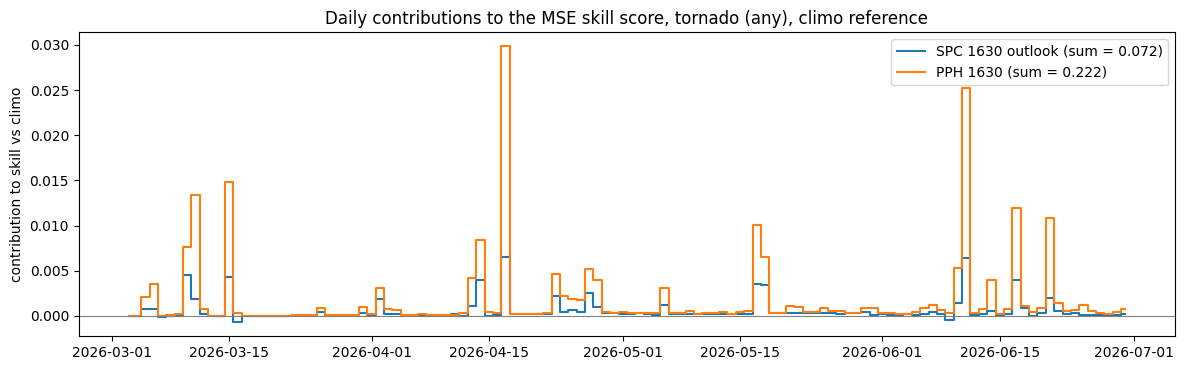

In [11]:
# Daily contributions to the period skill (they add up to SS); challenge-weighted as on slides 25-31
fig, ax = plt.subplots(figsize=(12, 3.8))
for name, m in results.items():
    d = m.groupby('date')[['se_fc', 'se_ref']].sum()
    c = (d.se_ref - d.se_fc) / d.se_ref.sum()
    ax.plot(c.index, c.values, drawstyle='steps-mid', label=f'{name} (sum = {c.sum():.3f})')
ax.axhline(0, color='0.5', lw=0.8); ax.legend(); ax.set_ylabel('contribution to skill vs climo')
ax.set_title('Daily contributions to the MSE skill score, tornado (any), climo reference')
plt.tight_layout(); plt.show()

## Notes on `do_verf_climo.ipynb`
- **Sorting levels.** The levels are sorted with `sort_values(by='title')`, which sorts the label strings alphabetically. That works for the tornado files, where every label is below 10%. For labels of 10% and above (your wind setup goes to `'12.00 '`), `'10.00 '` sorts before `'2.00 '`, which would mix up the "at or above" unions.
- **Domain remainder row.** `climoproj.loc[nlvls-1, ...]` writes the 0% remainder into row `nlvls - 1`. That is only a new row if the file has exactly `nlvls - 1` features. For `_1` (9 features) or `_3` (11 features), it would overwrite a real level, or misplace the remainder.
- **Band value.** The label (lower edge) is the forecast value for the whole band, so climo is biased low. `BAND_VALUE = 'mid'` changes that here.
- **Shared with `do_verf_outlooks.ipynb`.** The time-zone (MST) and hour-rounding window issues apply here too. The window was `>= 12Z` and `<= 12Z` with hour-ceiling times.